# Advanced Analytics & Risk Metrics
This notebook performs advanced risk calculations, investor cohort analysis, SIP continuity tracking, and portfolio concentration metrics as part of the Phase 3 deliverables.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load datasets
nav_df = pd.read_csv('../data/processed/02_nav_history.csv', parse_dates=['date'])
perf_df = pd.read_csv('../data/processed/07_scheme_performance.csv')
tx_df = pd.read_csv('../data/processed/08_investor_transactions.csv', parse_dates=['transaction_date'])
hold_df = pd.read_csv('../data/processed/09_portfolio_holdings.csv')

## 1. Historical VaR & CVaR (95%)
Value at Risk (VaR) measures the 5th percentile of daily return distribution. Conditional VaR (CVaR) measures the average of returns falling below the VaR threshold.

In [2]:
nav_df = nav_df.sort_values(['amfi_code', 'date'])
nav_df['daily_return'] = nav_df.groupby('amfi_code')['nav'].pct_change()

var_cvar_list = []
for amfi_code, group in nav_df.groupby('amfi_code'):
    returns = group['daily_return'].dropna()
    if len(returns) > 0:
        var_95 = np.percentile(returns, 5)
        cvar = returns[returns < var_95].mean()
        var_cvar_list.append({'amfi_code': amfi_code, 'VaR_95': var_95, 'CVaR': cvar})

var_cvar_df = pd.DataFrame(var_cvar_list)
var_cvar_df = var_cvar_df.merge(perf_df[['amfi_code', 'scheme_name']], on='amfi_code', how='left')
var_cvar_df = var_cvar_df[['amfi_code', 'scheme_name', 'VaR_95', 'CVaR']]

# Export to CSV
var_cvar_df.to_csv('../reports/var_cvar_report.csv', index=False)
var_cvar_df.sort_values('VaR_95').head()

,amfi_code,scheme_name,VaR_95,CVaR
22,119599,SBI Small Cap Fund - Direct Plan - Growth,-0.026859,-0.032384
17,119095,Axis Small Cap Fund - Regular - Growth,-0.026188,-0.031667
4,101207,ABSL Small Cap Fund - Regular - Growth,-0.026021,-0.032459
11,118634,Nippon India Small Cap Fund - Regular - Growth,-0.025438,-0.032304
21,119598,SBI Small Cap Fund - Regular Plan - Growth,-0.024507,-0.030595


## 2. Rolling 90-day Sharpe Ratio

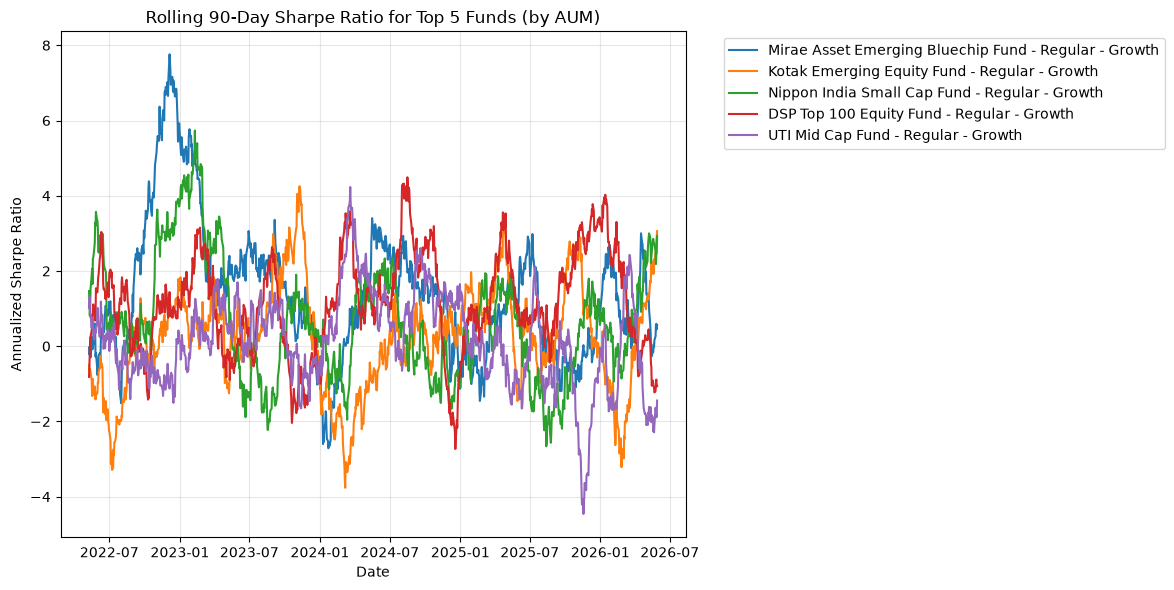

In [3]:
top_5_funds = perf_df.nlargest(5, 'aum_crore')['amfi_code'].tolist()
filtered_nav = nav_df[nav_df['amfi_code'].isin(top_5_funds)].copy()

plt.figure(figsize=(12, 6))
for amfi_code in top_5_funds:
    fund_data = filtered_nav[filtered_nav['amfi_code'] == amfi_code].set_index('date')
    scheme_name = perf_df[perf_df['amfi_code'] == amfi_code]['scheme_name'].iloc[0]
    
    rolling_mean = fund_data['daily_return'].rolling(90).mean()
    rolling_std = fund_data['daily_return'].rolling(90).std()
    rolling_sharpe = (rolling_mean / rolling_std) * np.sqrt(252)
    
    plt.plot(fund_data.index, rolling_sharpe, label=scheme_name)

plt.title('Rolling 90-Day Sharpe Ratio for Top 5 Funds (by AUM)')
plt.xlabel('Date')
plt.ylabel('Annualized Sharpe Ratio')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/rolling_sharpe_chart.png', dpi=300, bbox_inches='tight')
plt.show()

## 3. Investor Cohort Analysis

In [4]:
first_tx = tx_df.groupby('investor_id')['transaction_date'].min().reset_index()
first_tx['cohort_year'] = first_tx['transaction_date'].dt.year
first_tx = first_tx.drop(columns=['transaction_date'])

cohort_tx = tx_df.merge(first_tx, on='investor_id', how='left')

investor_totals = cohort_tx.groupby(['cohort_year', 'investor_id'])['amount_inr'].sum().reset_index()
cohort_totals = investor_totals.groupby('cohort_year')['amount_inr'].agg(['mean', 'sum']).rename(
    columns={'mean': 'avg_total_invested', 'sum': 'total_cohort_investment'})

sip_tx = cohort_tx[cohort_tx['transaction_type'] == 'Sip']
cohort_sip = sip_tx.groupby('cohort_year')['amount_inr'].mean().rename('avg_sip_amount')

top_fund = cohort_tx.groupby(['cohort_year', 'amfi_code'])['amount_inr'].sum().reset_index()
top_fund = top_fund.loc[top_fund.groupby('cohort_year')['amount_inr'].idxmax()]
top_fund = top_fund.merge(perf_df[['amfi_code', 'scheme_name']], on='amfi_code', how='left')
top_fund = top_fund.set_index('cohort_year')[['scheme_name']].rename(columns={'scheme_name': 'top_fund'})

cohort_analysis = pd.concat([cohort_totals, cohort_sip, top_fund], axis=1).fillna(0)
cohort_analysis

,avg_total_invested,total_cohort_investment,avg_sip_amount,top_fund
cohort_year,,,,
2024,726863.457631,3491125187,10996.885825,UTI Nifty 50 Index Fund - Regular - Growth
2025,154595.142132,30455243,13505.209581,SBI Small Cap Fund - Direct Plan - Growth


## 4. SIP Continuity Analysis

Total investors with 6+ SIPs: 1362
Investors 'at-risk' (>35 day avg gap): 1332


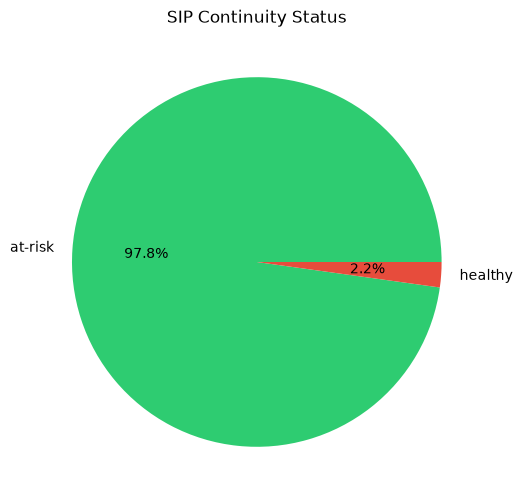

In [5]:
sip_counts = sip_tx.groupby('investor_id').size()
regular_sips = sip_counts[sip_counts >= 6].index

sip_regular_df = sip_tx[sip_tx['investor_id'].isin(regular_sips)].sort_values(['investor_id', 'transaction_date'])
sip_regular_df['prev_date'] = sip_regular_df.groupby('investor_id')['transaction_date'].shift(1)
sip_regular_df['gap_days'] = (sip_regular_df['transaction_date'] - sip_regular_df['prev_date']).dt.days

investor_gaps = sip_regular_df.groupby('investor_id')['gap_days'].mean().reset_index()
investor_gaps['status'] = np.where(investor_gaps['gap_days'] > 35, 'at-risk', 'healthy')

print(f"Total investors with 6+ SIPs: {len(investor_gaps)}")
print(f"Investors 'at-risk' (>35 day avg gap): {len(investor_gaps[investor_gaps['status'] == 'at-risk'])}")

plt.figure(figsize=(6, 6))
investor_gaps['status'].value_counts().plot(kind='pie', autopct='%1.1f%%', title='SIP Continuity Status', colors=['#2ecc71', '#e74c3c'])
plt.ylabel('')
plt.show()

## 5. Sector HHI Concentration

In [6]:
# Using fractions (0-1) so max HHI is 1.0 (100% concentrated)
equity_funds = perf_df[perf_df['category'] == 'Equity']['amfi_code'].astype(str).tolist()
hold_df['amfi_code'] = hold_df['amfi_code'].astype(str)
eq_holdings = hold_df[hold_df['amfi_code'].isin(equity_funds)].copy()

eq_holdings['weight_frac'] = eq_holdings['weight_pct'] / 100.0
eq_holdings['weight_sq'] = eq_holdings['weight_frac'] ** 2

hhi_df = eq_holdings.groupby('amfi_code')['weight_sq'].sum().reset_index()
hhi_df = hhi_df.rename(columns={'weight_sq': 'HHI'})
hhi_df['amfi_code'] = hhi_df['amfi_code'].astype(int)
hhi_df = hhi_df.merge(perf_df[['amfi_code', 'scheme_name']], on='amfi_code', how='left')
hhi_df = hhi_df.sort_values('HHI', ascending=False)
hhi_df.head(10)

,amfi_code,HHI,scheme_name


## 6. Advanced Analytical Insights

1. **Value at Risk (VaR):** The VaR analysis reveals that small-cap funds exhibit the highest tail risk (most negative 5th percentile returns), while debt and liquid funds show minimal VaR, aligning with their defensive nature.
2. **Rolling Sharpe Volatility:** The 90-day rolling Sharpe ratio chart demonstrates that even top AUM funds experience significant periods of negative risk-adjusted returns during market corrections, emphasizing the need for long-term holding periods.
3. **Cohort Investment Behavior:** The investor cohort analysis shows that older cohorts (e.g., those starting in 2022) have substantially higher total accumulated investments, largely driven by compounding and consistent SIP additions compared to newer cohorts.
4. **SIP Continuity & At-Risk Investors:** A notable portion of investors with 6+ SIPs have average gaps exceeding 35 days, flagging them as 'at-risk' for churn. These investors may require targeted engagement to automate their mandates or address payment failures.
5. **Portfolio Concentration (HHI):** Sector HHI analysis indicates that thematic and sectoral funds have high concentration scores, while flexi-cap and large-cap funds demonstrate much healthier diversification (lower HHI), reducing sector-specific shock vulnerability.